# TP3 - CNNs en imágenes satelitales

> Utilizaremos el dataset EuroSAT para entrenar un modelo de redes neuronales convolucionales. La idea principal es identificar distintos tipos de uso del suelo a través de imágenes.

> Para crear el modelo de CNNs utilizaremos la biblioteca *PyTorch*. Esta biblioteca es de aprendizaje automático y deep learning. Podemos crear tensores, usar diferenciación automática y construir redes neuronales.

**Descripción del dataset.** EuroSAT contiene imágenes satelitales del satélite Sentinel-2 (versión RGB).
Cada imagen tiene 64 × 64 píxeles y cada píxel cubre 10 m × 10 m de terreno, por lo que una imagen
representa un área de 640 m × 640 m. Hay 10 clases de uso del suelo:

| Clase | Descripción |
|---|---|
| AnnualCrop | Cultivos que se siembran y cosechan cada año (parcelas rectangulares) |
| PermanentCrop | Cultivos permanentes: viñedos, frutales, olivares |
| Pasture | Pasturas para ganado |
| HerbaceousVegetation | Vegetación herbácea natural, sin uso agrícola |
| Forest | Bosques |
| Highway | Rutas y autopistas |
| Industrial | Zonas industriales y comerciales |
| Residential | Zonas residenciales |
| River | Ríos |
| SeaLake | Mar y lagos |


In [1]:
# Bibliotecas

import pandas as pd
import torch
import matplotlib.pyplot as plt 
from torchvision import transforms
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn # Para crear la CNN.
import time # Para no pasarnos de tiempo en el entrenamiento.
import copy # Para guardar una copia de los pesos de la mejor época.

# Seed

torch.manual_seed(42)

# Directorio de datos

DATA_DIR = "EuroSAT" # Directorio donde se encuentran los datos.

#### 1- Realizamos un análisis exploratorio de los datos (EDA).

> Lo realizamos para mirar y entender los datos antes de modelar. Sin entrenar, podemos hacernos preguntas sobre el dataset.

> Podemos detectar problemas antes de entrenar, tomar decisiones de preprocesamiento y anticipar resultados.

In [2]:
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
validation_df = pd.read_csv(f"{DATA_DIR}/validation.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")

In [3]:
train_df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,16257,AnnualCrop/AnnualCrop_142.jpg,0,AnnualCrop
1,3297,HerbaceousVegetation/HerbaceousVegetation_2835...,2,HerbaceousVegetation
2,17881,PermanentCrop/PermanentCrop_1073.jpg,6,PermanentCrop
3,2223,Industrial/Industrial_453.jpg,4,Industrial
4,4887,HerbaceousVegetation/HerbaceousVegetation_1810...,2,HerbaceousVegetation


In [4]:
validation_df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,258,Pasture/Pasture_1481.jpg,5,Pasture
1,2134,Forest/Forest_2638.jpg,1,Forest
2,3518,Highway/Highway_875.jpg,3,Highway
3,3048,River/River_434.jpg,8,River
4,3996,SeaLake/SeaLake_2930.jpg,9,SeaLake


In [5]:
test_df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,2438,AnnualCrop/AnnualCrop_1275.jpg,0,AnnualCrop
1,1018,Residential/Residential_504.jpg,7,Residential
2,3,Pasture/Pasture_787.jpg,5,Pasture
3,1011,Residential/Residential_1575.jpg,7,Residential
4,47,Pasture/Pasture_473.jpg,5,Pasture


In [6]:
# Limpieza de datos:
# Descartamos la primera columna que no aporta valor alguno. Solamente es el indice que tenia en la fila en el dataset original.

test_df = test_df.drop(columns=["Unnamed: 0"])

validation_df = validation_df.drop(columns=["Unnamed: 0"])

train_df = train_df.drop(columns=["Unnamed: 0"])

In [7]:
# Tamaño de los datasets:

test_df.shape[0]

2700

In [8]:
validation_df.shape[0]

5400

In [9]:
train_df.shape[0]

18900

In [ ]:
import matplotlib.pyplot as plt

# 1) Datos: nombre y cantidad de imágenes de cada split
nombres = ["Train", "Validation", "Test"]
tamaños = [len(train_df), len(validation_df), len(test_df)]  # len() = cantidad de filas
total = sum(tamaños)

# 2) Etiquetas con nombre, cantidad y porcentaje
etiquetas = [
    f"{nombre}\n{tamaño:,} imágenes ({tamaño / total:.0%})"
    for nombre, tamaño in zip(nombres, tamaños)
]

# 3) Gráfico de torta
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    tamaños,
    labels=etiquetas,
    colors=["#2a78d6", "#eb6834", "#1baf7a"],     # un color distinto por split
    startangle=90,                                # arranca desde arriba
    counterclock=False,                           # gira en sentido horario
    wedgeprops={"edgecolor": "white", "linewidth": 2},  # separa las porciones
    textprops={"fontsize": 11},
)
ax.set_title(f"División del dataset EuroSAT ({total:,} imágenes)", fontsize=13)
plt.show()


> Como vemos, la división de datasets está en formato estándar de simple holdout set + validation, y tenemos imágenes de sobra como para entrenar, validar y testear el modelo.

> **¿Las clases están balanceadas?**


In [ ]:
# Cantidad de imágenes por clase en cada split
conteos = pd.DataFrame({
    "Train": train_df["ClassName"].value_counts(),
    "Validation": validation_df["ClassName"].value_counts(),
    "Test": test_df["ClassName"].value_counts(),
})

# Proporción de cada clase dentro de su split (cada columna suma 1)
proporciones = pd.DataFrame({
    "Train": train_df["ClassName"].value_counts(normalize=True),
    "Validation": validation_df["ClassName"].value_counts(normalize=True),
    "Test": test_df["ClassName"].value_counts(normalize=True),
})

# Ordenamos de mayor a menor según train
orden = conteos["Train"].sort_values(ascending=False).index
conteos = conteos.loc[orden]
proporciones = proporciones.loc[orden]

print("Cantidad de imágenes por clase:")
print(conteos)
print("\nProporción de cada clase por split (%):")
print((proporciones * 100).round(1))


In [ ]:
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
proporciones.plot.bar(ax=ax, color=["#2a78d6", "#eb6834", "#1baf7a"], width=0.8)
ax.set_title("Proporción de imágenes por clase en cada split")
ax.set_xlabel("")
ax.set_ylabel("Proporción dentro del split")
plt.xticks(rotation=45, ha="right")
plt.show()


> Como vemos en las tablas y el gráfico generado, hay un desbalance leve por ClassName. En train, las clases más grandes tienen 2.100 imágenes (11,1%) y la más chica, Pasture, tiene 1.400 (7,4%), un 33% menos.

> También vemos que cada split tiene la misma proporción de clases, así que la división es estratificada.

> El data augmentation que vamos a usar no corrige este desbalance, porque se aplica a todas las clases por igual. Lo usamos para que el modelo generalice mejor.

> Como el desbalance es leve, accuracy es una métrica que podemos utilizar, pero la vamos a complementar con métricas por clase para controlar Pasture.

> **¿Hay imágenes duplicadas?**


In [ ]:
# Juntamos los tres splits para chequear duplicados entre ellos
todos_df = pd.concat([train_df, validation_df, test_df])

# ¿Alguna imagen aparece más de una vez (dentro de un split o en dos splits distintos)?
print(f"Filas totales: {len(todos_df)}")
print(f"Archivos repetidos: {todos_df['Filename'].duplicated().sum()}")

# ¿La clase de cada fila coincide con la carpeta donde está la imagen?
carpeta = todos_df["Filename"].str.split("/").str[0]
print(f"Filas donde la carpeta no coincide con ClassName: {(carpeta != todos_df['ClassName']).sum()}")

# ¿Cada clase tiene un único Label numérico?
print(todos_df.groupby("ClassName")["Label"].unique())


In [ ]:
# ¿Los Label coinciden con label_map.json?
label_map = pd.read_json(f"{DATA_DIR}/label_map.json", typ="series")
print(f"Filas donde Label no coincide con label_map.json: {(todos_df['ClassName'].map(label_map) != todos_df['Label']).sum()}")

# ¿Hay imágenes con los mismos píxeles, dentro de un split o entre splits?
todas_imagenes = torch.stack([torch.from_numpy(plt.imread(f"{DATA_DIR}/{archivo}")) for archivo in todos_df["Filename"]])
imagenes_distintas = len(torch.unique(todas_imagenes.view(len(todas_imagenes), -1), dim=0))
print(f"Imágenes con contenido distinto: {imagenes_distintas} de {len(todas_imagenes)}")

> En el resultado vemos que no hay imágenes repetidas entre los datasets train, validation y test: ningún archivo se repite y las 27.000 imágenes tienen contenido distinto. Esto descarta copias exactas, pero no imágenes muy parecidas.

> Si hubiera imágenes iguales en train y en test, estaríamos ante un caso de data leakage.

> **¿A qué tipo de imágenes nos enfrentamos? ¿Cuáles se parecen?**

In [ ]:
# Mostramos 5 imágenes de cada clase (mismo esquema que la grilla de MNIST de la Práctica 13)
n_ejemplos = 5
fig, axs = plt.subplots(len(orden), n_ejemplos, figsize=(10, 20), constrained_layout=True)

for i, clase in enumerate(orden):
    # Filtramos las imágenes de esta clase y tomamos 5 al azar (random_state para reproducibilidad)
    ejemplos = train_df[train_df["ClassName"] == clase].sample(n_ejemplos, random_state=42)

    for j, archivo in enumerate(ejemplos["Filename"]):
        imagen = plt.imread(f"{DATA_DIR}/{archivo}")  # lee el .jpg como array (64, 64, 3)
        axs[i, j].imshow(imagen)
        axs[i, j].axis("off")

    axs[i, 0].set_title(clase, loc="left", fontsize=11)

plt.show()


> Vemos que, en algunos casos, las imágenes se parecen mucho: Pasture vs HerbaceousVegetation (las dos son verde claro sin estructura), AnnualCrop vs PermanentCrop (las dos son parcelas agrícolas), Highway vs River (las dos son una línea que cruza la imagen), Industrial vs Residential (las dos son construcciones) y SeaLake vs Forest (las dos son de un solo color).

> Lo tenemos en cuenta para el modelado y para después entender los resultados.

> **Cargamos las imágenes en tensores.**

In [10]:
# Leemos cada imagen de train y la pasamos a tensor
lista_imagenes = [torch.from_numpy(plt.imread(f"{DATA_DIR}/{archivo}")) for archivo in train_df["Filename"]]

# Apilamos todas en un solo tensor: (cantidad, alto, ancho, canales)
imagenes_train = torch.stack(lista_imagenes, dim=0)

# Aplanamos cada imagen a un vector de 64*64*3 y contamos cuántas filas distintas hay
imagenes_unicas = torch.unique(imagenes_train.view(len(imagenes_train), -1), dim=0)
print(f"Imágenes con contenido distinto: {len(imagenes_unicas)} de {len(imagenes_train)}")

print(f"Forma del tensor: {imagenes_train.shape}")
print(f"Tipo de dato: {imagenes_train.dtype}")
print(f"Valor mínimo: {imagenes_train.min()}, valor máximo: {imagenes_train.max()}")


/var/folders/2q/30d_v6b14rj3wdbgqs0zg4180000gn/T/ipykernel_45606/3160317140.py:2: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:212.)
  lista_imagenes = [torch.from_numpy(plt.imread(f"{DATA_DIR}/{archivo}")) for archivo in train_df["Filename"]]


Imágenes con contenido distinto: 18900 de 18900
Forma del tensor: torch.Size([18900, 64, 64, 3])
Tipo de dato: torch.uint8
Valor mínimo: 0, valor máximo: 255


> Cada imagen es un tensor de 3 dimensiones: alto × ancho × canales. Los canales son los 3 colores RGB (red, green, blue), y cada píxel tiene un valor entre 0 y 255 por canal.

> Vemos también que no hay dos imágenes de train con exactamente los mismos píxeles: las 18.900 filas de los tensores son distintas.

In [11]:
# Escalamos a [0, 1]: pasamos a float y dividimos por 255
imagenes_train = imagenes_train.float() / 255

# Media y desvío por canal: reducimos sobre imágenes, alto y ancho (dims 0, 1, 2) y queda solo el canal
media = torch.mean(imagenes_train, dim=(0, 1, 2))
desvio = torch.std(imagenes_train, dim=(0, 1, 2))

print(f"Media por canal (R, G, B): {media}")
print(f"Desvío por canal (R, G, B): {desvio}")


Media por canal (R, G, B): tensor([0.3445, 0.3803, 0.4078])
Desvío por canal (R, G, B): tensor([0.2041, 0.1369, 0.1150])


> Normalizamos igual que con StandardScaler en ML. Queremos que los tensores estén centrados en 0 y con std de 1.

> Primero, escalamos a [0, 1] dividiendo por 255.

| Canal | Media | Desvío |
|---|---|---|
| R (rojo) | 0.3445 | 0.2031 |
| G (verde) | 0.3803 | 0.1371 |
| B (azul) | 0.4078 | 0.1157 |

> Vemos que todas las medias están debajo de 0,5. Significa que, en promedio, son imágenes bastante oscuras.

> El canal azul tiene la media más grande, y es el canal más alto en 8 de las 10 clases (todas menos AnnualCrop y PermanentCrop). No se explica por River o SeaLake: sus medias de azul (0.381 y 0.349) están por debajo de la media general.

In [ ]:
import seaborn as sns

# Color promedio de cada imagen: promediamos alto y ancho (dims 1, 2) → (18900, 3)
color_por_imagen = torch.mean(imagenes_train, dim=(1, 2))

color_df = pd.DataFrame(color_por_imagen.numpy(), columns=["R", "G", "B"])
color_df["ClassName"] = train_df["ClassName"].values  # mismo orden en que cargamos las imágenes

fig, axs = plt.subplots(3, 1, figsize=(11, 12), constrained_layout=True, sharex=True)
for ax, canal, color in zip(axs, ["R", "G", "B"], ["#d62728", "#2ca02c", "#1f77b4"]):
    sns.boxplot(data=color_df, x="ClassName", y=canal, order=orden, ax=ax, color=color)
    ax.set_title(f"Intensidad media del canal {canal} por imagen, según clase")
    ax.set_xlabel("")
    ax.set_ylabel(f"Media de {canal} (0 a 1)")
plt.xticks(rotation=45, ha="right")
plt.show()


In [ ]:
# Valores exactos de los boxplots, para citarlos en el análisis
print("Media por clase:")
print(color_df.groupby("ClassName")[["R", "G", "B"]].mean().round(3))
print("\nDesvío por clase:")
print(color_df.groupby("ClassName")[["R", "G", "B"]].std().round(3))
print("\nPercentiles 25, 50 y 75 por clase:")
print(color_df.groupby("ClassName")[["R", "G", "B"]].quantile([0.25, 0.5, 0.75]).round(3))

> Vemos que Forest es la clase con los tonos más oscuros de todas (medias R 0.155, G 0.253, B 0.298) y la de menor dispersión en los tres canales (desvíos entre 0.025 y 0.032). Sus colores son muy consistentes entre imágenes.

> Industrial tiene el azul más alto (mediana 0.513). Lo podemos tener en cuenta al analizar sus predicciones.

> En general, la mayoría de las cajas queda por debajo de 0.5, pero no todas. El percentil 75 supera 0.5 en AnnualCrop (R 0.624, G 0.535, B 0.509), PermanentCrop (R 0.585, G 0.517) e Industrial (R 0.532, G 0.529, B 0.567).

> El color separa bien algunas clases: el percentil 75 de rojo de Forest (0.167) queda por debajo del percentil 25 de todas las demás clases, salvo SeaLake. En otras, las distribuciones se superponen mucho, como AnnualCrop vs PermanentCrop (medianas R 0.500 vs 0.482, G 0.460 vs 0.442, B 0.456 vs 0.434) y Pasture vs River (R 0.232 vs 0.251, G 0.336 vs 0.334, B 0.338 vs 0.375). Por eso, la CNN que implementemos tendrá que aprender mucho más que el color para predecir bien.

### Conclusiones del EDA

**1. Estructura del dataset**
- 27.000 imágenes RGB de 64 × 64 píxeles (10 m por píxel, 640 m × 640 m por imagen), en 10 clases de uso del suelo.
- División train / validation / test de 18.900 (70%), 5.400 (20%) y 2.700 (10%) imágenes.
- Verificamos que ningún archivo se repite y que no hay dos imágenes con exactamente los mismos píxeles, ni dentro de un split ni entre splits (sin data leakage por copias exactas). También verificamos que la clase de cada fila coincide con su carpeta y con `label_map.json`.

**2. Distribución de clases**
- Desbalance leve: las clases más grandes tienen 2.100 imágenes en train y la más chica (Pasture) 1.400, un 33% menos.
- La división es estratificada: cada clase tiene la misma proporción en los tres splits.
- Como el desbalance es leve, usaremos accuracy como métrica principal, complementada con precision, recall y F1 por clase para controlar el rendimiento en Pasture.

**3. Características visuales y clases difíciles**
- Por inspección visual, los pares que más se parecen son: AnnualCrop vs PermanentCrop, Pasture vs HerbaceousVegetation, Highway vs River, Industrial vs Residential y SeaLake vs Forest.
- Conclusión: el color no alcanza para distinguir varias clases. La red necesita aprender patrones de textura y forma, que es lo que capturan los filtros convolucionales de una CNN.

**4. Decisiones de preprocesamiento**
- No hace falta redimensionar: todas las imágenes miden 64 × 64.
- Escalamos los píxeles a [0, 1] y normalizamos por canal con la media (0.3445, 0.3803, 0.4078) y el desvío (0.2031, 0.1371, 0.1157) calculados solo sobre train, para evitar data leakage.
- Aplicaremos data augmentation geométrica (flips y rotaciones), porque en imágenes satelitales no existe un "arriba": un bosque rotado sigue siendo un bosque. Esto ayuda a que la red generalice mejor.


#### 2- Arquitectura custom y entrenamiento desde cero.

> Después del análisis de datos (EDA), modelamos desde cero una CNN simple, con herramientas vistas en las clases teóricas y prácticas.

> La idea es hacer un pipeline que normalice los datos para que el modelo generalice mejor, usar data augmentation geométrica y realizar el loop de entrenamiento.

> Después de que termine, vemos gráficos de loss y accuracy en train y validation. También monitoreamos el gradiente de las primeras iteraciones.

In [12]:
def cargar_split(df):
    """Carga las imágenes de un split como tensores (N, 3, 64, 64) normalizados, y sus labels."""
    a_tensor = transforms.ToTensor()  # (64, 64, 3) uint8 → (3, 64, 64) float en [0, 1]
    X = torch.stack([a_tensor(plt.imread(f"{DATA_DIR}/{archivo}")) for archivo in df["Filename"]])

    # Normalizamos cada canal con la media y el desvío de TRAIN (calculados en el EDA)
    # .view(1, 3, 1, 1) acomoda los 3 valores para que se apliquen canal por canal
    X = (X - media.view(1, 3, 1, 1)) / desvio.view(1, 3, 1, 1)

    y = torch.tensor(df["Label"].values)  # clases como números del 0 al 9
    return X, y

X_train, y_train = cargar_split(train_df)
X_val, y_val = cargar_split(validation_df)
X_test, y_test = cargar_split(test_df)

print(f"Train:      X {tuple(X_train.shape)}, y {tuple(y_train.shape)}")
print(f"Validation: X {tuple(X_val.shape)}, y {tuple(y_val.shape)}")
print(f"Test:       X {tuple(X_test.shape)}, y {tuple(y_test.shape)}")
print(f"Media por canal en train después de normalizar: {X_train.mean(dim=(0, 2, 3))}")
print(f"Desvío por canal en train después de normalizar: {X_train.std(dim=(0, 2, 3))}")


Train:      X (18900, 3, 64, 64), y (18900,)
Validation: X (5400, 3, 64, 64), y (5400,)
Test:       X (2700, 3, 64, 64), y (2700,)
Media por canal en train después de normalizar: tensor([-1.3832e-07, -2.0650e-07, -1.1070e-07])
Desvío por canal en train después de normalizar: tensor([1., 1., 1.])


> En los resultados observamos que la media es cercana a 0 y el std es cercano a 1. Entonces, la normalización de datos resultó de manera favorable.

> NO hay leakage porque en el EDA calculamos la media y el desvío solamente con las imágenes de train. No le estamos mostrando al modelo la distribución de test.

> Vamos a dividir las imágenes en batches para entrenar el modelo. Si le pasáramos todas las imágenes juntas, actualizaríamos los pesos una sola vez por época y cada actualización sería muy costosa. Con batches actualizamos los pesos 296 veces por época, con menos cómputo en cada una.

> Para cada batch se calculará la loss y se hará backpropagation para mejorar el modelo.

> El batch size que elegimos es de 64 imágenes, el mismo valor que usamos en la Práctica 13.

In [13]:
BATCH_SIZE = 64

# Train se mezcla en cada época; validation no hace falta, porque solo se usa para medir
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)

print(f"Batches por época: train = {len(train_loader)}, validation = {len(val_loader)}")

# Miramos un batch para entender qué devuelve el DataLoader
x_batch, y_batch = next(iter(train_loader))
print(f"Forma de un batch de imágenes: {tuple(x_batch.shape)}")  # (64, 3, 64, 64)
print(f"Forma de un batch de labels:   {tuple(y_batch.shape)}")  # (64,)
print(f"Labels del batch: {y_batch[:10]}")


Batches por época: train = 296, validation = 85
Forma de un batch de imágenes: (64, 3, 64, 64)
Forma de un batch de labels:   (64,)
Labels del batch: tensor([8, 0, 2, 2, 2, 8, 6, 4, 9, 0])


> *Data Augmentation en deep learning*: con CNNs, el modelo puede entrenarse y aprender a leer las imágenes de forma muy específica. Entonces, usamos data augmentation para modificar en cierta manera estas imágenes en cada iteración. Lo que hacemos es espejar y rotar las imágenes en cada batch. De esta manera reducimos el riesgo de overfitting, aunque no lo eliminamos.

> En MNIST no funcionaría ya que, por ejemplo, rotar un 6 lo convierte en un 9. Pero en EuroSAT no modifica la clase porque son imágenes satelitales de territorios. No hay arriba o abajo ni orientaciones fijas.

In [14]:
def aumentar(x):
    """Aplica flips y rotaciones de 90° al azar, independientes para cada imagen del batch.
    x tiene forma (batch, canales, alto, ancho)."""
    x = x.clone()  # copia, para no modificar el batch original
    n = len(x)

    # Flip horizontal a la mitad de las imágenes (al azar)
    elegidas = torch.rand(n) < 0.5
    x[elegidas] = torch.flip(x[elegidas], dims=[3])  # dim 3 = ancho → espejo izquierda-derecha

    # Flip vertical a la mitad de las imágenes (al azar)
    elegidas = torch.rand(n) < 0.5
    x[elegidas] = torch.flip(x[elegidas], dims=[2])  # dim 2 = alto → espejo arriba-abajo

    # Rotación: a cada imagen le sorteamos 0, 1, 2 o 3 giros de 90°
    giros = torch.randint(0, 4, (n,))
    for k in range(1, 4):
        elegidas = giros == k
        x[elegidas] = torch.rot90(x[elegidas], k, dims=[2, 3])  # gira en el plano alto-ancho

    return x


> El código rota al azar las imágenes de cada batch. Realiza rotaciones en múltiplos de 90 grados. Si rotáramos en ángulos que no son múltiplos de 90 grados, tendríamos imágenes con bordes negros y no ayudaría al entrenamiento.

In [ ]:
# Tomamos una imagen de train y generamos 7 versiones aumentadas
imagen = X_train[0]
versiones = aumentar(imagen.repeat(7, 1, 1, 1))  # repeat: 7 copias de la misma imagen → (7, 3, 64, 64)
todas = torch.cat([imagen.unsqueeze(0), versiones])  # original + 7 aumentadas → (8, 3, 64, 64)

# Para mostrarlas: deshacemos la normalización y pasamos a (alto, ancho, canales)
todas = todas * desvio.view(1, 3, 1, 1) + media.view(1, 3, 1, 1)
todas = todas.permute(0, 2, 3, 1).clamp(0, 1)

fig, axs = plt.subplots(1, 8, figsize=(16, 2.5), constrained_layout=True)
for i, ax in enumerate(axs):
    ax.imshow(todas[i])
    ax.set_title("Original" if i == 0 else f"Aumentada {i}", fontsize=10)
    ax.axis("off")
plt.suptitle(f"Data augmentation sobre una imagen de {train_df['ClassName'].iloc[0]}")
plt.show()


> **Ahora, definimos la CNN.**

In [ ]:
torch.manual_seed(0)  # inicialización de pesos reproducible

red = nn.Sequential(
    # Bloque 1: (3, 64, 64) → (32, 32, 32)
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Bloque 2: (32, 32, 32) → (64, 16, 16)
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Bloque 3: (64, 16, 16) → (128, 8, 8)
    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Clasificador
    nn.Flatten(),                 # (128, 8, 8) → vector de 8192
    nn.Linear(128 * 8 * 8, 128),
    nn.ReLU(),                    # ← la salida de esta capa es el espacio latente (Parte 2)
    nn.Linear(128, 10),           # un puntaje por clase
)
print(red)

In [ ]:
x = x_batch  # el batch de 64 imagenes.
print(f"{'Entrada':<12} {tuple(x.shape)}")
with torch.no_grad():
    for capa in red:
        x = capa(x)
        n_param = sum(p.numel() for p in capa.parameters())
        print(f"{type(capa).__name__:<12} {str(tuple(x.shape)):<22} parámetros: {n_param:,}")

print(f"\nParámetros totales: {sum(p.numel() for p in red.parameters()):,}")


> Función de entrenamiento

In [15]:
def evaluar(red, loader, criterion):
    """Devuelve la loss promedio y el accuracy de la red sobre un DataLoader, sin entrenar."""
    red.eval()  # modo evaluación
    loss_total, aciertos, n = 0, 0, 0
    with torch.no_grad():  # no calculamos gradientes: solo medimos
        for x, y in loader:
            salida = red(x)
            loss_total += criterion(salida, y).item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            n += len(y)
    return loss_total / n, aciertos / n


def entrenar(red, n_epocas, lr=0.001, epocas_gradientes=3):
    """Entrena la red con augmentation y registra métricas, gradientes y tiempo por época."""
    optimizer = torch.optim.Adam(red.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    # Capas con pesos (Conv2d y Linear): de estas registramos los gradientes
    capas_con_pesos = [i for i, capa in enumerate(red) if isinstance(capa, (nn.Conv2d, nn.Linear))]

    historia = {"loss_train": [], "acc_train": [], "loss_val": [], "acc_val": [], "tiempo": []}
    gradientes = {i: [] for i in capas_con_pesos}

    for epoca in range(n_epocas):
        inicio = time.time()
        red.train()  # modo entrenamiento
        loss_total, aciertos, n = 0, 0, 0

        for x, y in train_loader:
            x = aumentar(x)  # data augmentation, solo en train

            optimizer.zero_grad()           # 1. borrar los gradientes anteriores
            salida = red(x)                 # 2. forward
            loss = criterion(salida, y)     #    medir el error
            loss.backward()                 # 3. backward: calcular gradientes
            
            # Guardamos la norma del gradiente de cada capa (solo las primeras épocas)
            if epoca < epocas_gradientes:
                for i in capas_con_pesos:
                    gradientes[i].append(red[i].weight.grad.norm().item())

            optimizer.step()                # 4. actualizar los pesos

            # Acumulamos las métricas de train del batch
            loss_total += loss.item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            n += len(y)

        # Fin de la época: métricas de train y validation
        historia["loss_train"].append(loss_total / n)
        historia["acc_train"].append(aciertos / n)
        loss_val, acc_val = evaluar(red, val_loader, criterion)
        historia["loss_val"].append(loss_val)
        historia["acc_val"].append(acc_val)
        historia["tiempo"].append(time.time() - inicio)

        print(f"Época {epoca + 1:2d}/{n_epocas} | "
              f"loss train {historia['loss_train'][-1]:.3f}, val {loss_val:.3f} | "
              f"acc train {historia['acc_train'][-1]:.3f}, val {acc_val:.3f} | "
              f"{historia['tiempo'][-1]:.0f} s")

    return historia, gradientes


> Entreno con 15 épocas:

In [ ]:
N_EPOCAS = 15

torch.manual_seed(0)

historia_cnn, gradientes_cnn = entrenar(red, N_EPOCAS)

In [ ]:
epocas = range(1, N_EPOCAS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

ax1.plot(epocas, historia_cnn["loss_train"], "o-", label="Train", color="#2a78d6")
ax1.plot(epocas, historia_cnn["loss_val"], "o-", label="Validation", color="#eb6834")
ax1.set_title("Loss (Cross-Entropy) por época")
ax1.set_xlabel("Época")
ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(epocas, historia_cnn["acc_train"], "o-", label="Train", color="#2a78d6")
ax2.plot(epocas, historia_cnn["acc_val"], "o-", label="Validation", color="#eb6834")
ax2.set_title("Accuracy por época")
ax2.set_xlabel("Época")
ax2.set_ylabel("Accuracy")
ax2.legend()
plt.show()


> Después de entrenar la CNN, vemos que la loss baja muchísimo tanto en train como en validation: en la época 15 llega a 0.148 y 0.185.

> El accuracy (que vimos anteriormente que podemos utilizar ya que el desbalance de clases es leve) sube muchísimo y llega a 0.949 en train y 0.937 en validation.

> Sin contar dos épocas con tiempos anómalos (1272 s y 1250 s), cada época tardó 105.4 ± 10.8 s con una laptop sin GPU. A ese ritmo, las 15 épocas tardan unos 26 minutos.

> No detectamos overfitting viendo la loss porque no se ve una distancia notable entre validation y train. En la época 14 vemos que subió con respecto a train, pero en la época 15 bajó.

> Voy a reentrenar con más épocas porque en 15 épocas parecía que la loss seguía mejorando. Intentaré con 25 épocas.

> Si hay pocas épocas, puede haber underfitting. Si hay muchas épocas, puede haber overfitting.

> ¿Si entrenamos con 25 épocas puede aparecer overfitting? Sí, puede aparecer en las últimas épocas, pero no afecta al modelo final porque guardamos los pesos de la mejor época según validation. Usamos la idea de early stopping: entrenamos todas las épocas y nos quedamos con la mejor.

In [16]:
torch.manual_seed(0)  # inicialización de pesos reproducible

red_v2 = nn.Sequential(
    # Bloque 1: (3, 64, 64) → (32, 32, 32)
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Bloque 2: (32, 32, 32) → (64, 16, 16)
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Bloque 3: (64, 16, 16) → (128, 8, 8)
    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Clasificador
    nn.Flatten(),                 # (128, 8, 8) → vector de 8192
    nn.Linear(128 * 8 * 8, 128),
    nn.ReLU(),                    # ← la salida de esta capa es el espacio latente (Parte 2)
    nn.Linear(128, 10),           # un puntaje por clase
)

In [17]:
def entrenar_v2(red, n_epocas, lr=0.001, epocas_gradientes=3):
    """Igual que entrenar(), pero al final deja cargados los pesos de la época
    con mejor accuracy en validation (early stopping)."""
    optimizer = torch.optim.Adam(red.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    capas_con_pesos = [i for i, capa in enumerate(red) if isinstance(capa, (nn.Conv2d, nn.Linear))]

    historia = {"loss_train": [], "acc_train": [], "loss_val": [], "acc_val": [], "tiempo": []}
    gradientes = {i: [] for i in capas_con_pesos}
    mejor_acc, mejor_epoca, mejor_estado = 0, 0, None  # NUEVO respecto de entrenar()

    for epoca in range(n_epocas):
        inicio = time.time()
        red.train()
        loss_total, aciertos, n = 0, 0, 0

        for x, y in train_loader:
            x = aumentar(x)

            optimizer.zero_grad()
            salida = red(x)
            loss = criterion(salida, y)
            loss.backward()

            if epoca < epocas_gradientes:
                for i in capas_con_pesos:
                    gradientes[i].append(red[i].weight.grad.norm().item())

            optimizer.step()

            loss_total += loss.item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            n += len(y)

        historia["loss_train"].append(loss_total / n)
        historia["acc_train"].append(aciertos / n)
        loss_val, acc_val = evaluar(red, val_loader, criterion)
        historia["loss_val"].append(loss_val)
        historia["acc_val"].append(acc_val)
        historia["tiempo"].append(time.time() - inicio)

        # NUEVO: si esta época es la mejor en validation, guardamos una copia de los pesos
        if acc_val > mejor_acc:
            mejor_acc, mejor_epoca = acc_val, epoca + 1
            mejor_estado = copy.deepcopy(red.state_dict())

        print(f"Época {epoca + 1:2d}/{n_epocas} | "
              f"loss train {historia['loss_train'][-1]:.3f}, val {loss_val:.3f} | "
              f"acc train {historia['acc_train'][-1]:.3f}, val {acc_val:.3f} | "
              f"{historia['tiempo'][-1]:.0f} s")

    # NUEVO: la red termina con los pesos de la mejor época
    red.load_state_dict(mejor_estado)
    print(f"\nMejor época: {mejor_epoca} (accuracy validation = {mejor_acc:.3f})")
    historia["mejor_epoca"] = mejor_epoca
    return historia, gradientes


In [ ]:
N_EPOCAS_V2 = 25

torch.manual_seed(0)

historia_v2, gradientes_v2 = entrenar_v2(red_v2, N_EPOCAS_V2)

In [ ]:
epocas_v2 = range(1, N_EPOCAS_V2 + 1)
mejor = historia_v2["mejor_epoca"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

ax1.plot(epocas_v2, historia_v2["loss_train"], "o-", label="Train", color="#2a78d6")
ax1.plot(epocas_v2, historia_v2["loss_val"], "o-", label="Validation", color="#eb6834")
ax1.axvline(mejor, color="gray", linestyle="--", label=f"Mejor época ({mejor})")
ax1.set_title("Loss (Cross-Entropy) por época – 25 épocas")
ax1.set_xlabel("Época")
ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(epocas_v2, historia_v2["acc_train"], "o-", label="Train", color="#2a78d6")
ax2.plot(epocas_v2, historia_v2["acc_val"], "o-", label="Validation", color="#eb6834")
ax2.axvline(mejor, color="gray", linestyle="--", label=f"Mejor época ({mejor})")
ax2.set_title("Accuracy por época – 25 épocas")
ax2.set_xlabel("Época")
ax2.set_ylabel("Accuracy")
ax2.legend()
plt.show()

> Con 25 épocas, el mejor accuracy de validation se alcanza en la época 22 (0.952, loss 0.142), y nos quedamos con esos pesos. En las épocas siguientes, el accuracy de validation oscila entre 0.936 y 0.951, sin una caída sostenida, por lo que no hay evidencia clara de overfitting. La loss de train sigue bajando (0.088 en la época 25) y la de validation oscila (0.150 en la época 25), así que la brecha podría seguir creciendo si entrenáramos más. Como la época 22 se eligió usando validation, su 0.952 es algo optimista: la estimación honesta del desempeño se obtiene en test (Parte 2).



In [ ]:
# Guardamos los pesos de la mejor época para no tener que reentrenar
torch.save(red_v2.state_dict(), "red_v2.pt")

# Para recuperarlos: ejecutar la celda de red_v2 y después
# red_v2.load_state_dict(torch.load("red_v2.pt"))

In [ ]:
nombres_capas = ["Conv 1", "Conv 2", "Conv 3", "Linear 1", "Linear 2"]
batches_por_epoca = len(train_loader)

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
for nombre, normas in zip(nombres_capas, gradientes_v2.values()):
    ax.plot(normas, label=nombre, linewidth=1)

# Líneas verticales que marcan el fin de cada época
for e in range(1, 3):
    ax.axvline(e * batches_por_epoca, color="gray", linestyle="--", linewidth=1)

ax.set_yscale("log")
ax.set_title("Norma del gradiente por capa durante las primeras 3 épocas")
ax.set_xlabel("Batch (las líneas punteadas separan las épocas)")
ax.set_ylabel("Norma del gradiente (escala log)")
ax.legend()
plt.show()


In [ ]:
resumen = {}
for nombre, normas in zip(nombres_capas, gradientes_v2.values()):
    normas = torch.tensor(normas)
    resumen[nombre] = {
        f"Época {e + 1}": normas[e * batches_por_epoca:(e + 1) * batches_por_epoca].mean().item()
        for e in range(3)
    }
    resumen[nombre]["Desvío"] = normas.std().item()
    resumen[nombre]["Mínimo"] = normas.min().item()
    resumen[nombre]["Máximo"] = normas.max().item()

print(pd.DataFrame(resumen).T.round(4))


> Como se ve en el gráfico y la tabla de los gradientes por capa, no tenemos el problema de vanishing gradients. Conv 1, la capa más lejana a la salida, tiene normas promedio de 4.2, 5.6 y 6.0 por época. Su norma solo es baja en los primeros batches (mínimo 0.025), y después sube y se estabiliza.

> Tampoco tenemos exploding gradients: la norma máxima es 26.7 y, aunque hay picos entre batches, no crece sin control. Esto significa que el gradiente llega a todas las capas durante el inicio del entrenamiento.

> Esto es consistente con que la red tiene pocas capas (5 con pesos) y con que usamos ReLU como función de activación, cuya derivada vale 1 en las neuronas activas. Con la sigmoide, cuya derivada vale como máximo 0.25, los gradientes se achican más al propagarse.

> No comparamos magnitudes entre capas, porque la norma depende de la cantidad de pesos de cada una. Además, esta conclusión vale para las primeras 3 épocas, que son las que medimos.

In [18]:
red_v2.load_state_dict(torch.load("red_v2.pt"))
loss_val, acc_val = evaluar(red_v2, val_loader, nn.CrossEntropyLoss())
print(f"Validation: loss {loss_val:.3f}, accuracy {acc_val:.3f}")

Validation: loss 0.138, accuracy 0.953


#### 3- Análisis de Errores y Espacio Latente.

> > Evaluamos el modelo final (`red_v2`) por primera y única vez sobre el conjunto de test (2.700 imágenes). Esto nos da una estimación no sesgada del rendimiento general y por clase mediante Accuracy, Precision, Recall y F1-Score.

In [19]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Nombres de las clases ordenados según su Label (0 a 9)
clases = train_df.groupby("Label")["ClassName"].first().tolist()

test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

def predecir(red, loader):
    """Devuelve la clase predicha para cada imagen del loader."""
    red.eval()
    predicciones = []
    with torch.no_grad():
        for x, y in loader:
            predicciones.append(red(x).argmax(dim=1))
    return torch.cat(predicciones)

pred_custom = predecir(red_v2, test_loader)
print("Reporte de Clasificación en Test (red_v2)")
print(classification_report(y_test, pred_custom, target_names=clases, digits=3))

Reporte de Clasificación en Test (red_v2)
                      precision    recall  f1-score   support

          AnnualCrop      0.938     0.950     0.944       300
              Forest      0.990     0.980     0.985       300
HerbaceousVegetation      0.922     0.947     0.934       300
             Highway      0.955     0.932     0.943       250
          Industrial      0.971     0.944     0.957       250
             Pasture      0.962     0.885     0.922       200
       PermanentCrop      0.940     0.932     0.936       250
         Residential      0.977     0.997     0.987       300
               River      0.903     0.964     0.932       250
             SeaLake      0.987     0.983     0.985       300

            accuracy                          0.954      2700
           macro avg      0.954     0.951     0.953      2700
        weighted avg      0.955     0.954     0.954      2700



> ### Análisis del rendimiento en Test:
> - **Rendimiento global:** `red_v2` alcanza un **Accuracy de 0.954 (95.4%)** y un **Macro F1-score de 0.953** sobre las 2.700 imágenes de test. Este resultado es sumamente consistente con el accuracy obtenido en validación (0.952), lo que demuestra que el modelo generaliza de forma honesta y no sufrió sobreajuste (overfitting) a la partición de validación durante la selección de hiperparámetros.
> - **Clases con mejor desempeño:** Las clases más precisas son **Residential** (F1: 0.987, recall 0.997), **Forest** (F1: 0.985, recall 0.980) y **SeaLake** (F1: 0.985, recall 0.983). Estas categorías presentan patrones espectrales y espaciales muy definidos (alta densidad de bordes en techos residenciales, tonos oscuros continuos en bosques y cuerpos de agua homogéneos).
> - **Clases con menor desempeño:** La clase más desafiante para la red es **Pasture**, con el F1-score más bajo (**0.922**) y un recall de apenas **0.885** (deja sin clasificar al 11.5% de sus instancias). Le siguen **River** (F1: 0.932) y **HerbaceousVegetation** (F1: 0.934).
> - **Desempeño en Pasture:** Si bien tiene una alta precisión (0.962, cuando predice Pasture rara vez se equivoca), sufre un recall bajo. Esto se explica en parte por ser la clase minoritaria en el conjunto de test (support de 200 imágenes frente a 250–300 del resto) y por su marcada similitud visual y colorimétrica con otros tipos de cobertura vegetal abierta.

> Construimos la matriz de confusión sobre el conjunto de test para identificar qué clases clasifica con mayor precisión y cuáles confunde con mayor frecuencia, calculando la proporción de errores relativos a cada clase real.

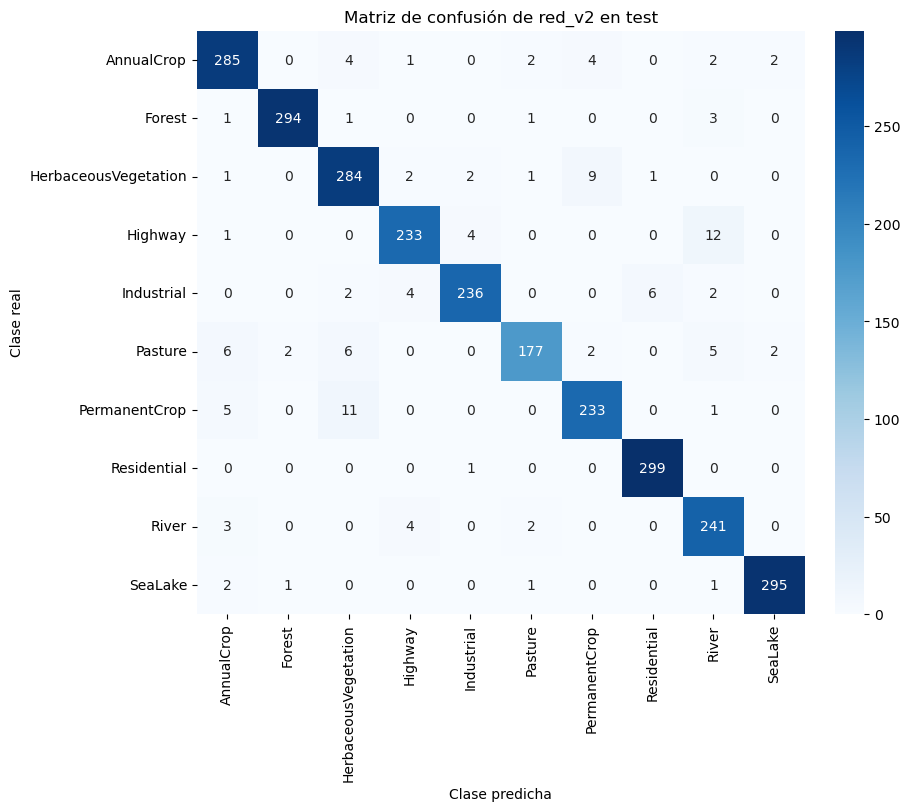

Top 10 confusiones más frecuentes:
                   Real              Predicha  Errores  % de la clase real
0               Highway                 River       12                 4.8
1         PermanentCrop  HerbaceousVegetation       11                 4.4
2  HerbaceousVegetation         PermanentCrop        9                 3.0
3               Pasture  HerbaceousVegetation        6                 3.0
4               Pasture            AnnualCrop        6                 3.0
5            Industrial           Residential        6                 2.4
6         PermanentCrop            AnnualCrop        5                 2.0
7               Pasture                 River        5                 2.5
8            AnnualCrop  HerbaceousVegetation        4                 1.3
9                 River               Highway        4                 1.6


In [20]:
matriz = confusion_matrix(y_test, pred_custom)

fig, ax = plt.subplots(figsize=(9, 8), constrained_layout=True)
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=clases, yticklabels=clases, ax=ax)
ax.set_title("Matriz de confusión de red_v2 en test")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
plt.show()

# Ranking de las confusiones más frecuentes
confusiones = []
for i, real in enumerate(clases):
    for j, predicha in enumerate(clases):
        if i != j and matriz[i, j] > 0:
            confusiones.append({
                "Real": real, 
                "Predicha": predicha, 
                "Errores": matriz[i, j],
                "% de la clase real": round(100 * matriz[i, j] / matriz[i].sum(), 1)
            })

df_confusiones = pd.DataFrame(confusiones).sort_values("Errores", ascending=False).reset_index(drop=True)
print("Top 10 confusiones más frecuentes:")
print(df_confusiones.head(10))

> Inspeccionamos visualmente ejemplos de imágenes mal clasificadas para las confusiones más recurrentes, revirtiendo la normalización para observar los colores y texturas originales.

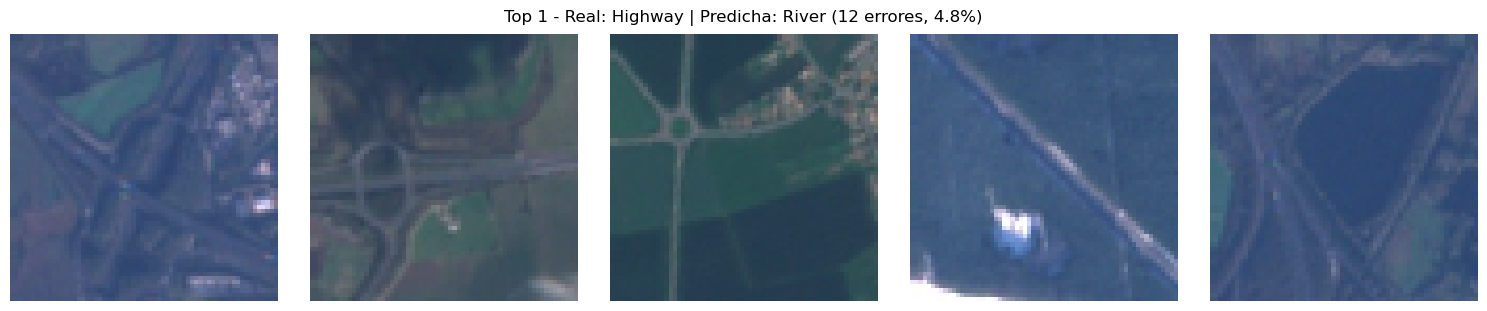

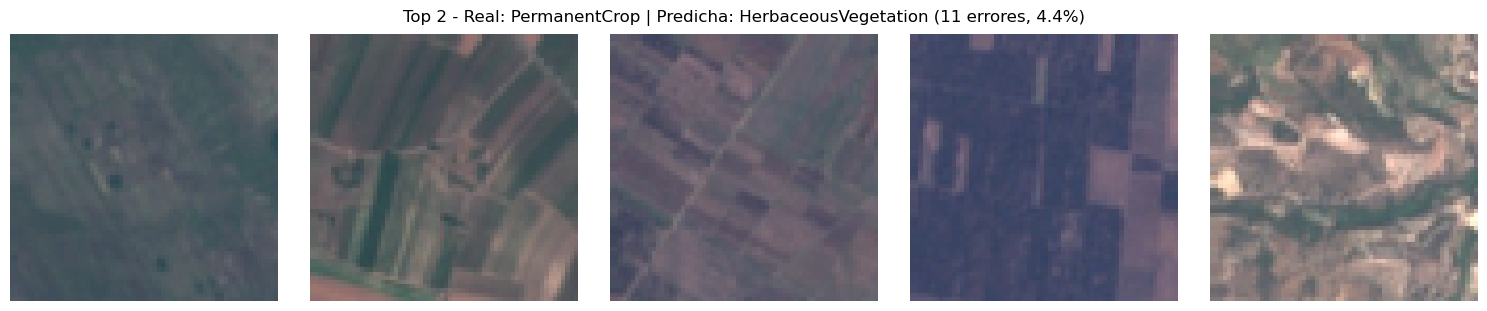

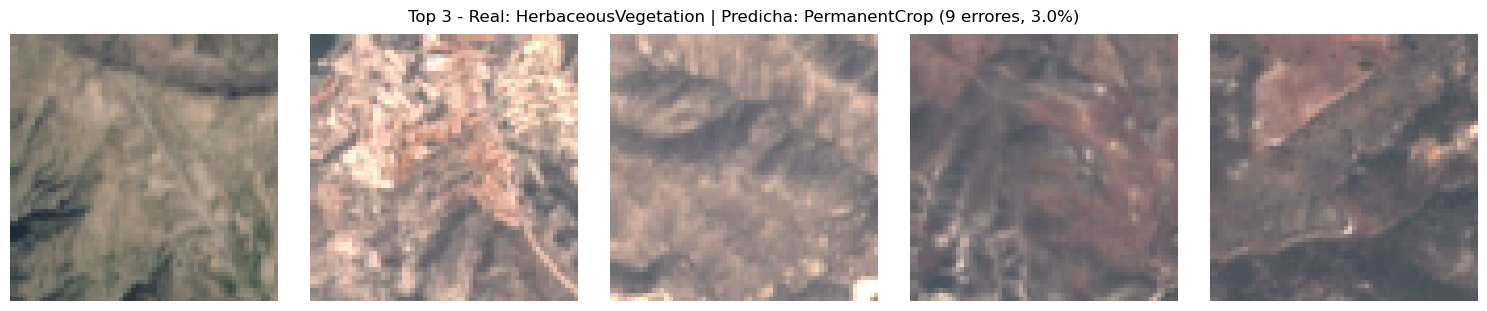

In [21]:
# Inspeccionamos las 3 confusiones principales del ranking
top_k = min(3, len(df_confusiones))

for k in range(top_k):
    fila = df_confusiones.iloc[k]
    clase_real_nombre = fila["Real"]
    clase_pred_nombre = fila["Predicha"]
    real_idx = clases.index(clase_real_nombre)
    pred_idx = clases.index(clase_pred_nombre)
    
    indices = ((y_test == real_idx) & (pred_custom == pred_idx)).nonzero().flatten()[:5]
    
    if len(indices) > 0:
        # Deshacemos la normalización para visualizar en espacio RGB original
        imagenes = X_test[indices] * desvio.view(1, 3, 1, 1) + media.view(1, 3, 1, 1)
        imagenes = imagenes.permute(0, 2, 3, 1).clamp(0, 1)
        
        fig, axs = plt.subplots(1, len(indices), figsize=(3 * len(indices), 3), constrained_layout=True, squeeze=False)
        for ax, img in zip(axs[0], imagenes):
            ax.imshow(img)
            ax.axis("off")
        plt.suptitle(f"Top {k+1} - Real: {clase_real_nombre} | Predicha: {clase_pred_nombre} ({fila['Errores']} errores, {fila['% de la clase real']}%)")
        plt.show()

> ### Análisis y Justificación de las Confusiones más Frecuentes:
> 
> Al analizar las 2.700 imágenes de test, observamos que los errores no son aleatorios, sino que se concentran en familias temáticas bien definidas:
> 
> 1. **Highway vs. River (12 errores, 4.8% de Highway; y 4 errores en sentido inverso, 1.6% de River):**
>    - Es la confusión individual más frecuente del modelo (12 casos donde una autopista se clasifica como río).
>    - **Justificación estructural:** Ambas clases corresponden a estructuras alargadas, lineales y continuas que atraviesan recortes topográficos. En imágenes satelitales de 64×64 píxeles a resolución Sentinel-2 (10 m/píxel), un tramo de asfalto oscuro, mojado o con sombras circundantes adquiere una firma espacial y tonal casi indistinguible de un río estrecho o canalizado.
> 
> 2. **Confusión cruzada en Cobertura Vegetal (PermanentCrop, HerbaceousVegetation, Pasture, AnnualCrop):**
>    - **PermanentCrop con HerbaceousVegetation:** 11 imágenes (4.4% de PermanentCrop). En sentido inverso, 9 imágenes de HerbaceousVegetation se predicen como PermanentCrop (3.0%).
>    - **Pasture con HerbaceousVegetation y AnnualCrop:** Pasture pierde 6 imágenes hacia HerbaceousVegetation (3.0%) y 6 hacia AnnualCrop (3.0%).
>    - **Justificación biológica y espectral:** Todas estas clases comparten firmas espectrales en las bandas RGB dominadas por la reflectancia verde/amarilla de la clorofila y el suelo expuesto. Dependiendo de la estación de captura del satélite (fenología agrícola), un cultivo perenne recién podado o en descanso se asemeja visualmente a vegetación herbácea, y una pastura natural se solapa morfológicamente con un cultivo anual o campo abierto.
> 
> 3. **Industrial vs. Residential (6 errores, 2.4% de Industrial):**
>    - 6 recortes industriales fueron clasificados como residenciales.
>    - **Justificación morfológica:** Ambas representan suelo urbano construido (zonas antropogénicas con techos, concreto, calles y estacionamientos). La distinción radica en la escala y forma de las edificaciones (naves industriales grandes versus manzanas con casas pequeñas), que a 64×64 píxeles puede volverse difusa en zonas mixtas periurbanas.

> Extraemos la representación interna de 128 dimensiones de cada imagen justo antes de la capa de clasificación lineal (`red_v2[:-1]`). Proyectamos este espacio latente en 2D mediante PCA y t-SNE para evaluar si las clases forman clusters distinguibles antes de la decisión final.

Forma de los features: (2700, 128)
Varianza explicada con 2 componentes: 0.410
Varianza explicada con 50 componentes: 0.986


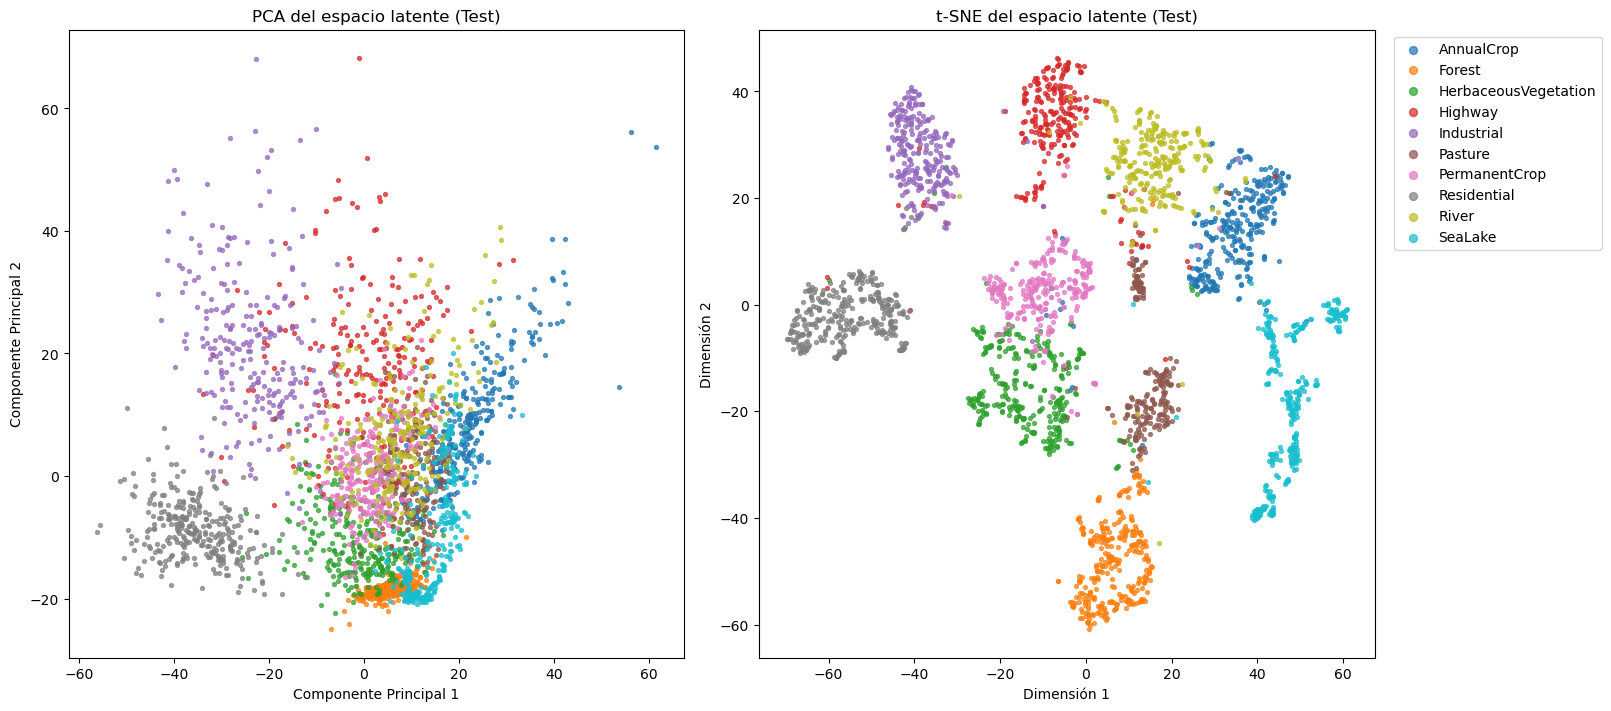

In [22]:
import os
# Evita el conflicto de hilos de OpenMP/PyTorch que crashea el kernel en scikit-learn
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

import gc
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# red_v2 sin su última capa lineal (vector latente de 128 características)
extractor = red_v2[:-1]
extractor.eval()

features_list = []
with torch.no_grad():
    for x, y in test_loader:
        salida = extractor(x)
        features_list.append(salida.cpu())

features = torch.cat(features_list, dim=0).numpy()
print(f"Forma de los features: {features.shape}")

# Limpiamos memoria intermedia
del features_list
gc.collect()

# PCA a 50 dimensiones
pca = PCA(n_components=50, random_state=0)
features_pca = pca.fit_transform(features)

print(f"Varianza explicada con 2 componentes: {pca.explained_variance_ratio_[:2].sum():.3f}")
print(f"Varianza explicada con 50 componentes: {pca.explained_variance_ratio_.sum():.3f}")

# t-SNE a 2 dimensiones (n_jobs=1 para evitar colisiones multihilo)
tsne = TSNE(n_components=2, perplexity=30, random_state=0, n_jobs=1)
coords_tsne = tsne.fit_transform(features_pca)

# Gráfico comparativo
fig, axs = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
y_test_np = y_test.numpy() if isinstance(y_test, torch.Tensor) else y_test

for i, clase in enumerate(clases):
    filtro = (y_test_np == i)
    axs[0].scatter(features_pca[filtro, 0], features_pca[filtro, 1], s=8, alpha=0.7, label=clase, color=plt.cm.tab10(i))
    axs[1].scatter(coords_tsne[filtro, 0], coords_tsne[filtro, 1], s=8, alpha=0.7, label=clase, color=plt.cm.tab10(i))

axs[0].set_title("PCA del espacio latente (Test)")
axs[0].set_xlabel("Componente Principal 1")
axs[0].set_ylabel("Componente Principal 2")

axs[1].set_title("t-SNE del espacio latente (Test)")
axs[1].set_xlabel("Dimensión 1")
axs[1].set_ylabel("Dimensión 2")
axs[1].legend(markerscale=2, bbox_to_anchor=(1.02, 1), loc="upper left")

plt.show()

> ### Análisis del Espacio Latente (PCA y t-SNE):
> 
> Analizamos la representación interna de 128 dimensiones extraída justo antes de la capa de clasificación lineal (`red_v2[:-1]`):
> 
> - **Compresión con PCA:** 
>   - Las primeras **2 componentes principales explican el 41.0%** de la varianza total de los features, mientras que **50 componentes retienen el 98.6%** de la información. Esto evidencia que el espacio latente de 128 dimensiones es altamente redundante y que prácticamente toda la estructura útil para discriminar clases reside en un subespacio de menor dimensión.
>   - En el plano PCA 2D se aprecia una separación global por grandes dominios (zonas urbanas construidas a la izquierda y coberturas naturales/vegetales hacia el centro e inferior), aunque con bastante solapamiento debido a la naturaleza estrictamente lineal de la proyección.
> 
> - **Estructura no lineal con t-SNE:**
>   - Al capturar relaciones de vecindad no lineales, **t-SNE revela clusters bien definidos y compactos** para la gran mayoría de las clases antes de la decisión final de la red.
>   - **Clusters altamente aislados:** Clases como **Residential** (gris, a la izquierda), **Industrial** (violeta, superior izquierda) y **Forest** (naranja, inferior) forman agrupaciones nítidas y distantes del resto. Esto coincide con sus altos F1-scores en test (0.987, 0.957 y 0.985, respectivamente). **SeaLake** (celeste, extrema derecha) también forma un continuo alargado bien separado.
> 
> - **Correspondencia directa con la Matriz de Confusión:**
>   - **Highway y River:** En el t-SNE, el cluster de **Highway** (rojo) y el de **River** (amarillo verdoso) se ubican contiguos en la parte superior, e incluso comparten puntos fronterizos intercalados. Esto justifica visualmente por qué representan la mayor confusión individual del modelo (12 falsos ríos en Highway y 4 en sentido inverso).
>   - **Familia de vegetación y cultivos:** Las clases **PermanentCrop** (rosa), **HerbaceousVegetation** (verde), **Pasture** (marrón) y **AnnualCrop** (azul) forman clusters adyacentes en el centro del mapa. Se observa que puntos periféricos de Pasture tocan a HerbaceousVegetation y a AnnualCrop, lo que explica por qué Pasture tuvo el menor recall (0.885) y dispersó errores hacia esas clases (6 errores hacia cada una).
> 
> **Conclusión sobre la representación interna:** Las clases ya se encuentran fuertemente separadas en el espacio latente de 128 dimensiones antes de la capa final. La última capa densa opera principalmente trazando hiperplanos de separación lineal sobre clusters que la parte convolucional ya organizó de forma coherente según la semántica visual del terreno.